I/Prétraitement et analyse exploratoire

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy import stats as st
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)

1.Chargement des données

In [29]:
df = pd.read_csv("../data/raw/data.csv")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [31]:
print(list(df.columns))
print(df["diagnosis"].value_counts())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
diagnosis
B    357
M    212
Name: count, dtype: int64


2.Traitement de la colonne parasite
La colonne `Unnamed: 32` est entièrement vide (569 valeurs manquantes sur 569).
On vérifie qu'elle ne contient aucune donnée, puis on la supprime. La colonne `id` est exclue des analyses et le diagnostic est codé B = 0, M = 1.

In [32]:
col = "Unnamed: 32"
print("Valeurs non nulles   :", df[col].notna().sum())
print("Valeurs manquantes   :", df[col].isna().sum(), "sur", len(df))
print("Valeurs distinctes   :", df[col].nunique(dropna=True))

Valeurs non nulles   : 0
Valeurs manquantes   : 569 sur 569
Valeurs distinctes   : 0


In [33]:
assert df[col].isna().all(), "La colonne contient des données : ne pas la supprimer !"

df_clean = df.drop(columns=[col])
print("Avant :", df.shape, "| Après :", df_clean.shape)

Avant : (569, 33) | Après : (569, 32)


In [34]:
print("id tous uniques :", df_clean["id"].is_unique)

df_clean["target"] = df_clean["diagnosis"].map({"B": 0, "M": 1})
print("Valeurs non codées :", df_clean["target"].isna().sum())

feature_cols = [c for c in df_clean.columns if c not in ("id", "diagnosis", "target")]
print("Nombre de variables :", len(feature_cols))

id tous uniques : True
Valeurs non codées : 0
Nombre de variables : 30


3.Audit de qualité des données
Contrôle des valeurs manquantes, des doublons, des valeurs impossibles et des
valeurs aberrantes (règle de l'IQR).

In [35]:
manquantes = df_clean[feature_cols + ["diagnosis"]].isna().sum()
print("Total de valeurs manquantes :", manquantes.sum())
print("Variables concernées :", (manquantes > 0).sum())

Total de valeurs manquantes : 0
Variables concernées : 0


In [36]:
print("Lignes entièrement dupliquées         :", df_clean.duplicated().sum())
print("Doublons sur les 30 mesures (sans id) :", df_clean.duplicated(subset=feature_cols).sum())
print("id dupliqués                          :", df_clean["id"].duplicated().sum())

Lignes entièrement dupliquées         : 0
Doublons sur les 30 mesures (sans id) : 0
id dupliqués                          : 0


In [37]:
print("Valeurs négatives :", (df_clean[feature_cols] < 0).sum().sum())

zeros = (df_clean[feature_cols] == 0).sum()
print("\nVariables contenant des zéros :")
print(zeros[zeros > 0])

Valeurs négatives : 0

Variables contenant des zéros :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


In [38]:
zero_cols = ["concavity_mean", "concave points_mean", "concavity_se",
             "concave points_se", "concavity_worst", "concave points_worst"]

lignes_zero = (df_clean[zero_cols] == 0).any(axis=1)
print("Patientes concernées :", lignes_zero.sum())
print(df_clean.loc[lignes_zero, "diagnosis"].value_counts())

# Sont-ce exactement les mêmes lignes pour les 6 variables ?
print("Mêmes lignes pour les 6 variables :",
      all(((df_clean[c] == 0) == (df_clean["concavity_mean"] == 0)).all() for c in zero_cols))

Patientes concernées : 13
diagnosis
B    13
Name: count, dtype: int64
Mêmes lignes pour les 6 variables : True


In [39]:
Q1 = df_clean[feature_cols].quantile(0.25)
Q3 = df_clean[feature_cols].quantile(0.75)
IQR = Q3 - Q1

masque = (df_clean[feature_cols] < Q1 - 1.5 * IQR) | (df_clean[feature_cols] > Q3 + 1.5 * IQR)

resume = pd.DataFrame({
    "nb_outliers": masque.sum(),
    "pct": (masque.mean() * 100).round(1)
}).sort_values("nb_outliers", ascending=False)

print(resume.head(10))
print("\nIndividus avec au moins un outlier :", masque.any(axis=1).sum(), "sur", len(df_clean))

                         nb_outliers   pct
area_se                           65  11.4
radius_se                         38   6.7
perimeter_se                      38   6.7
area_worst                        35   6.2
smoothness_se                     30   5.3
fractal_dimension_se              28   4.9
compactness_se                    28   4.9
symmetry_se                       27   4.7
area_mean                         25   4.4
fractal_dimension_worst           24   4.2

Individus avec au moins un outlier : 171 sur 569


In [40]:
out_par_classe = masque.groupby(df_clean["diagnosis"]).sum().sum(axis=1)
print("Outliers par classe (total sur les 30 variables) :")
print(out_par_classe)

Outliers par classe (total sur les 30 variables) :
diagnosis
B    139
M    469
dtype: int64


In [41]:
nb_out_indiv = masque.sum(axis=1)
print(nb_out_indiv.groupby(df_clean["diagnosis"]).agg(["mean", "median", "max"]).round(2))

print("\nPart des individus avec au moins un outlier :")
print((nb_out_indiv > 0).groupby(df_clean["diagnosis"]).mean().round(3))

           mean  median  max
diagnosis                   
B          0.39     0.0   10
M          2.21     1.0   18

Part des individus avec au moins un outlier :
diagnosis
B    0.160
M    0.538
dtype: float64


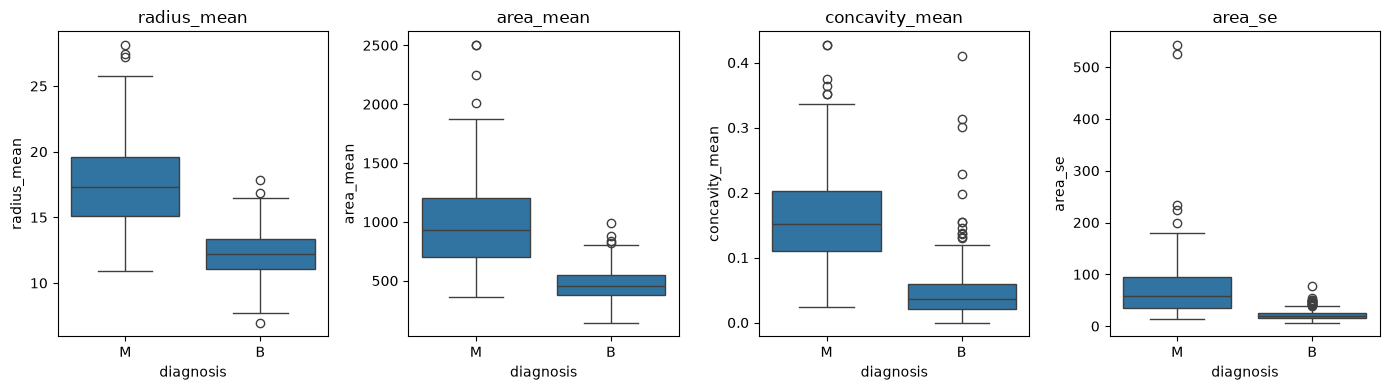

In [42]:
os.makedirs("../reports/figures", exist_ok=True)

vars_ex = ["radius_mean", "area_mean", "concavity_mean", "area_se"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, v in zip(axes, vars_ex):
    sns.boxplot(data=df_clean, x="diagnosis", y=v, ax=ax)
    ax.set_title(v)
plt.tight_layout()
plt.savefig("../reports/figures/boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

Standardisation (Z-score) 

In [43]:
echelles = df_clean[feature_cols].agg(["mean", "std", "min", "max"]).T
echelles["etendue"] = echelles["max"] - echelles["min"]

print("Variables à plus grande dispersion :")
print(echelles.sort_values("std", ascending=False).head(5).round(3))
print("\nVariables à plus faible dispersion :")
print(echelles.sort_values("std").head(5).round(4))

Variables à plus grande dispersion :
                    mean      std      min     max   etendue
area_worst       880.583  569.357  185.200  4254.0  4068.800
area_mean        654.889  351.914  143.500  2501.0  2357.500
area_se           40.337   45.491    6.802   542.2   535.398
perimeter_worst  107.261   33.603   50.410   251.2   200.790
perimeter_mean    91.969   24.299   43.790   188.5   144.710

Variables à plus faible dispersion :
                          mean     std     min     max  etendue
fractal_dimension_se    0.0038  0.0026  0.0009  0.0298   0.0289
smoothness_se           0.0070  0.0030  0.0017  0.0311   0.0294
concave points_se       0.0118  0.0062  0.0000  0.0528   0.0528
fractal_dimension_mean  0.0628  0.0071  0.0500  0.0974   0.0475
symmetry_se             0.0205  0.0083  0.0079  0.0790   0.0711


In [44]:
var = df_clean[feature_cols].var()
print("Plus grande variance :", var.idxmax(), "=", round(var.max(), 1))
print("Plus petite variance :", var.idxmin(), "=", var.min())
print("Rapport :", f"{var.max() / var.min():.2e}")

Plus grande variance : area_worst = 324167.4
Plus petite variance : fractal_dimension_se = 7.001691562872347e-06
Rapport : 4.63e+10


In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(df_clean[feature_cols]),
    columns=feature_cols,
    index=df_clean.index
)
X_scaled.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,2.489734,-0.565265,2.833031,2.487578,-0.214002,1.316862,0.724026,0.660820,1.148757,0.907083,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,0.499255,-0.876244,0.263327,0.742402,-0.605351,-0.692926,-0.440780,0.260162,-0.805450,-0.099444,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,1.228676,-0.780083,0.850928,1.181336,-0.297005,0.814974,0.213076,1.424827,0.237036,0.293559,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,0.326373,-0.110409,0.286593,-0.288378,0.689702,2.744280,0.819518,1.115007,4.732680,2.047511,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,1.270543,-0.790244,1.273189,1.190357,1.483067,-0.048520,0.828471,1.144205,-0.361092,0.499328,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


In [46]:
print("Moyenne maximale (en valeur absolue) :", X_scaled.mean().abs().max())
print("Écart-type min / max :",
      X_scaled.std(ddof=0).min().round(3), "/", X_scaled.std(ddof=0).max().round(3))

Moyenne maximale (en valeur absolue) : 8.366671932500301e-16
Écart-type min / max : 1.0 / 1.0


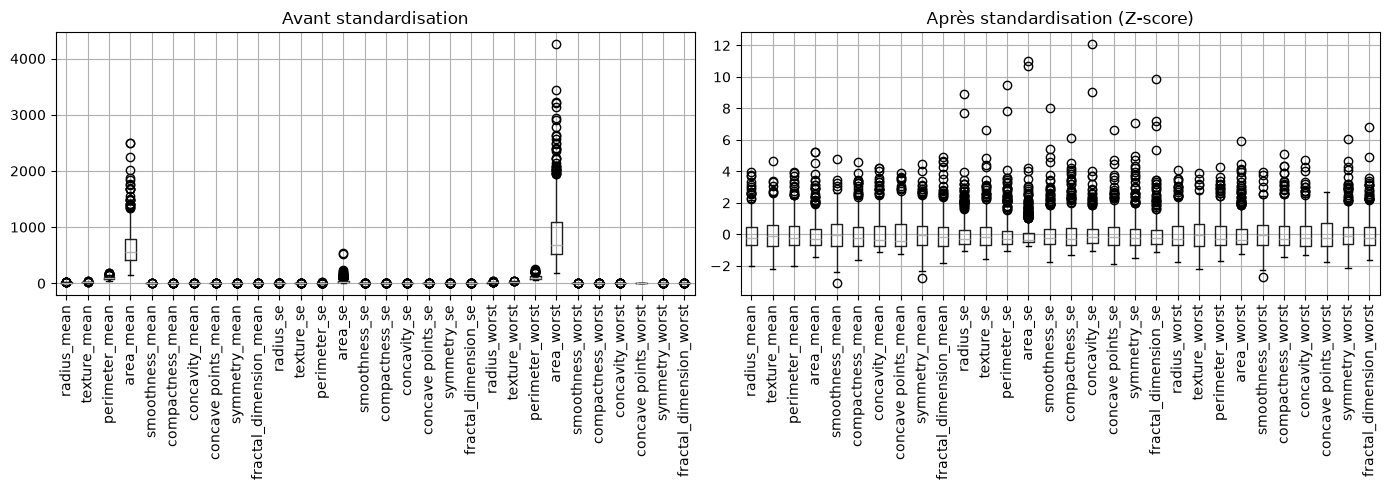

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_clean[feature_cols].boxplot(ax=axes[0], rot=90)
axes[0].set_title("Avant standardisation")

X_scaled.boxplot(ax=axes[1], rot=90)
axes[1].set_title("Après standardisation (Z-score)")

plt.tight_layout()
plt.savefig("../reports/figures/avant_apres_zscore.png", dpi=150, bbox_inches="tight")
plt.show()

Analyse statistique exploratoire

In [48]:
stats = df_clean[feature_cols].describe().T
stats["asymetrie"] = df_clean[feature_cols].skew()
stats.round(3)

,count,mean,std,min,25%,50%,75%,max,asymetrie
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110,0.942
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280,0.650
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500,0.991
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000,1.646
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163,0.456
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345,1.190
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427,1.401
concave points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201,1.171
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304,0.726
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097,1.304


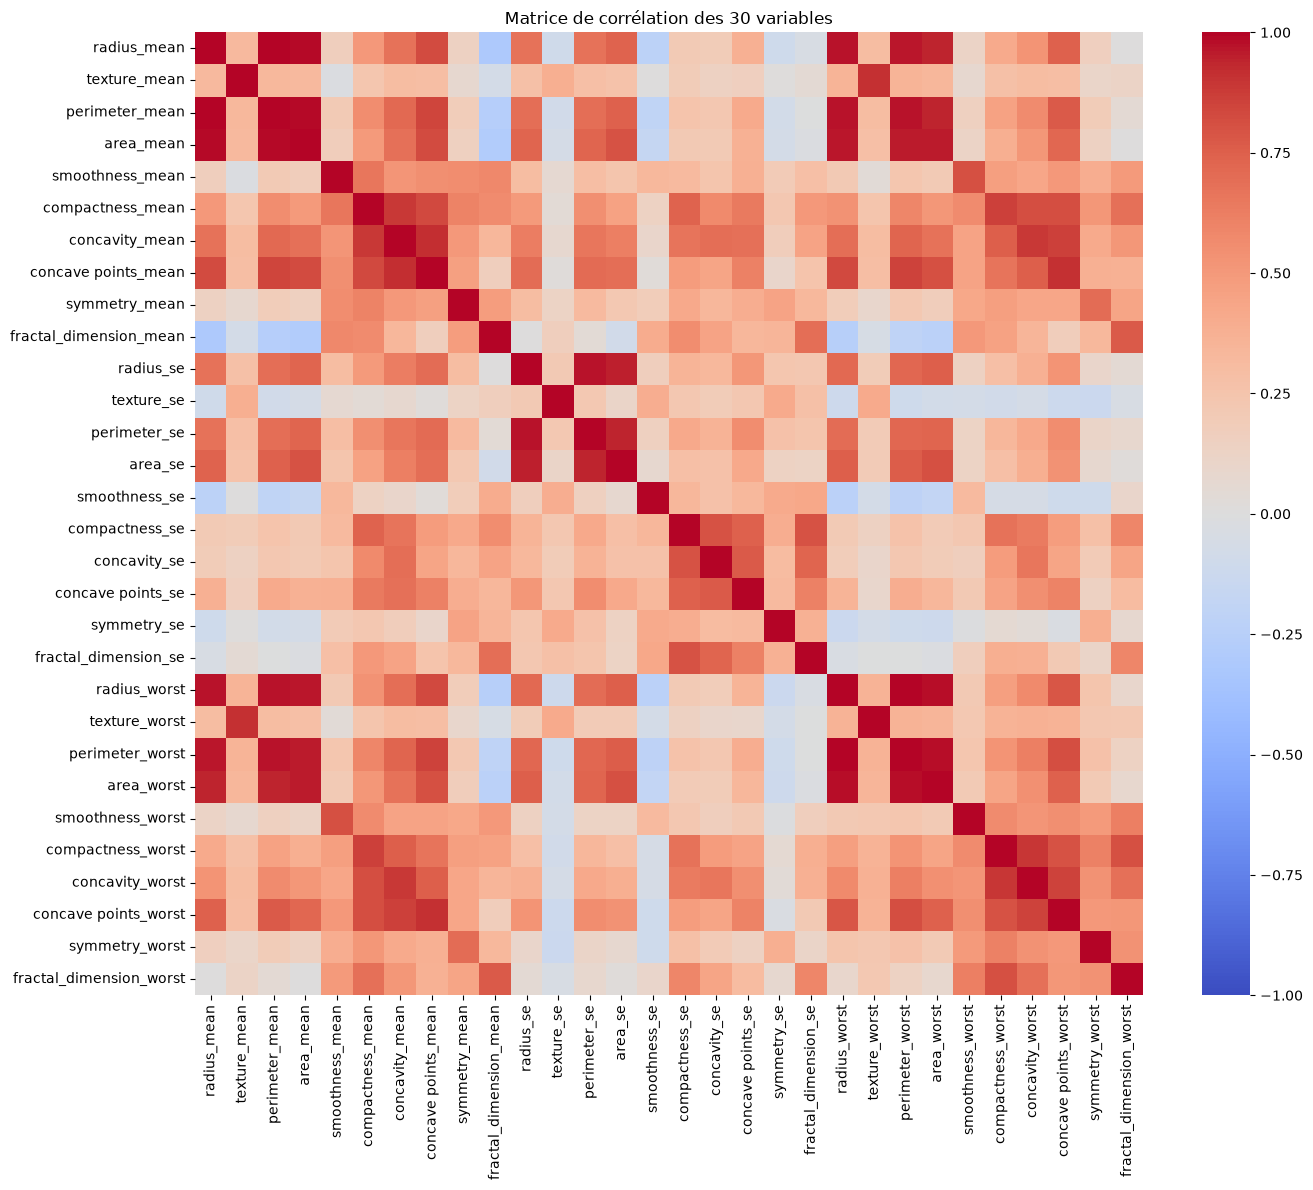

In [49]:
corr = df_clean[feature_cols].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.title("Matrice de corrélation des 30 variables")
plt.tight_layout()
plt.savefig("../reports/figures/matrice_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
paires = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack().rename("r").reset_index())
paires.columns = ["var1", "var2", "r"]
paires["abs_r"] = paires["r"].abs()

print("Paires avec |r| > 0.9 :", (paires["abs_r"] > 0.9).sum(), "sur", len(paires))
print("Paires avec |r| > 0.8 :", (paires["abs_r"] > 0.8).sum())
paires.sort_values("abs_r", ascending=False).head(15).round(4)

Paires avec |r| > 0.9 : 21 sur 900
Paires avec |r| > 0.8 : 44


,var1,var2,r,abs_r
2,radius_mean,perimeter_mean,0.9979,0.9979
622,radius_worst,perimeter_worst,0.9937,0.9937
3,radius_mean,area_mean,0.9874,0.9874
63,perimeter_mean,area_mean,0.9865,0.9865
623,radius_worst,area_worst,0.9840,0.9840
683,perimeter_worst,area_worst,0.9776,0.9776
312,radius_se,perimeter_se,0.9728,0.9728
82,perimeter_mean,perimeter_worst,0.9704,0.9704
20,radius_mean,radius_worst,0.9695,0.9695
80,perimeter_mean,radius_worst,0.9695,0.9695


In [51]:
trio = ["radius_mean", "perimeter_mean", "area_mean"]
print(df_clean[trio].corr().round(4))

trio_w = ["radius_worst", "perimeter_worst", "area_worst"]
print()
print(df_clean[trio_w].corr().round(4))

                radius_mean  perimeter_mean  area_mean
radius_mean          1.0000          0.9979     0.9874
perimeter_mean       0.9979          1.0000     0.9865
area_mean            0.9874          0.9865     1.0000

                 radius_worst  perimeter_worst  area_worst
radius_worst           1.0000           0.9937      0.9840
perimeter_worst        0.9937           1.0000      0.9776
area_worst             0.9840           0.9776      1.0000


In [52]:
valeurs_propres = np.linalg.eigvalsh(corr.values)[::-1]
part = valeurs_propres / valeurs_propres.sum()

print("Valeurs propres (5 premières) :", valeurs_propres[:5].round(3))
print("Part de la variance (5 premières) :", (part[:5] * 100).round(1))
print("Plus petite valeur propre :", valeurs_propres[-1])
print("Conditionnement :", f"{valeurs_propres[0] / valeurs_propres[-1]:.2e}")

Valeurs propres (5 premières) : [13.282  5.691  2.818  1.981  1.649]
Part de la variance (5 premières) : [44.3 19.   9.4  6.6  5.5]
Plus petite valeur propre : 0.0001330448228204979
Conditionnement : 9.98e+04


In [53]:
cov_brute = df_clean[feature_cols].cov()
cov_std = X_scaled.cov(ddof=0)

print("Covariance brute : de", cov_brute.values.min().round(2), "à", cov_brute.values.max().round(1))
print("Covariance des Z-scores = matrice de corrélation :", np.allclose(cov_std.values, corr.values))

Covariance brute : de -26.13 à 324167.4
Covariance des Z-scores = matrice de corrélation : True


Variables informatives

In [54]:
lignes = []
for v in feature_cols:
    b = df_clean.loc[df_clean["target"] == 0, v]
    m = df_clean.loc[df_clean["target"] == 1, v]
    s_pool = np.sqrt(((len(b) - 1) * b.var() + (len(m) - 1) * m.var()) / (len(b) + len(m) - 2))
    d = (m.mean() - b.mean()) / s_pool
    p = st.mannwhitneyu(m, b, alternative="two-sided").pvalue
    auc = roc_auc_score(df_clean["target"], df_clean[v])
    r = df_clean[v].corr(df_clean["target"])
    lignes.append((v, r, d, max(auc, 1 - auc), p))

informativite = pd.DataFrame(
    lignes, columns=["variable", "r_cible", "cohen_d", "auc", "p_mannwhitney"]
).set_index("variable")

informativite.sort_values("auc", ascending=False).round({"r_cible": 3, "cohen_d": 2, "auc": 3})

,r_cible,cohen_d,auc,p_mannwhitney
variable,,,,
perimeter_worst,0.783,2.60,0.975,2.583004e-80
radius_worst,0.776,2.54,0.970,1.135630e-78
area_worst,0.734,2.23,0.970,1.803309e-78
concave points_worst,0.794,2.69,0.967,1.863997e-77
concave points_mean,0.777,2.55,0.964,1.006324e-76
perimeter_mean,0.743,2.29,0.947,3.553870e-71
area_mean,0.709,2.08,0.938,1.539780e-68
concavity_mean,0.696,2.00,0.938,2.164549e-68
radius_mean,0.730,2.21,0.938,2.692943e-68


In [55]:
seuil_corr = 0.9   
seuil_auc = 0.7    

ordre = informativite.sort_values("auc", ascending=False)
retenues, ecartees = [], {}

for v in ordre.index:
    if ordre.loc[v, "auc"] < seuil_auc:
        ecartees[v] = "peu informative (AUC < 0.7)"
        continue
    redondantes = [w for w in retenues if abs(corr.loc[v, w]) >= seuil_corr]
    if redondantes:
        w = max(redondantes, key=lambda x: abs(corr.loc[v, x]))
        ecartees[v] = f"redondante avec {w} (r = {corr.loc[v, w]:.3f})"
    else:
        retenues.append(v)

print("Variables retenues :", len(retenues))
print(ordre.loc[retenues, ["auc", "cohen_d"]].round(3))
print("\nVariables écartées :", len(ecartees))
for v, raison in ecartees.items():
    print(f"- {v} : {raison}")

Variables retenues : 14
                        auc  cohen_d
variable                            
perimeter_worst       0.975    2.598
concave points_worst  0.967    2.693
concavity_mean        0.938    2.003
area_se               0.926    1.353
concavity_worst       0.921    1.812
compactness_mean      0.864    1.535
compactness_worst     0.862    1.513
concave points_se     0.792    0.923
texture_worst         0.785    1.061
concavity_se          0.781    0.542
smoothness_worst      0.754    0.960
symmetry_worst        0.737    0.945
compactness_se        0.727    0.633
smoothness_mean       0.722    0.793

Variables écartées : 16
- radius_worst : redondante avec perimeter_worst (r = 0.994)
- area_worst : redondante avec perimeter_worst (r = 0.978)
- concave points_mean : redondante avec concave points_worst (r = 0.910)
- perimeter_mean : redondante avec perimeter_worst (r = 0.970)
- area_mean : redondante avec perimeter_worst (r = 0.959)
- radius_mean : redondante avec perimeter_wor

In [57]:
sous_corr = corr.loc[retenues, retenues].abs()

# copie NumPy modifiable : on met la diagonale à 0 pour ignorer r(v, v) = 1
M = sous_corr.to_numpy(copy=True)
np.fill_diagonal(M, 0)
sous_corr = pd.DataFrame(M, index=sous_corr.index, columns=sous_corr.columns)

print("Corrélation max entre variables retenues :", M.max().round(3))

paires_max = (sous_corr.where(np.triu(np.ones(sous_corr.shape), k=1).astype(bool))
                       .stack().sort_values(ascending=False).head(5))
print(paires_max.round(3))

vp = np.linalg.eigvalsh(corr.loc[retenues, retenues].to_numpy(copy=True))
print("\nPlus petite valeur propre (14 variables) :", vp.min().round(4))
print("Conditionnement (14 variables) :", f"{vp.max() / vp.min():.1f}")

Corrélation max entre variables retenues : 0.892
concavity_worst       compactness_worst    0.892
concavity_mean        concavity_worst      0.884
                      compactness_mean     0.883
compactness_mean      compactness_worst    0.866
concave points_worst  concavity_mean       0.861
dtype: float64

Plus petite valeur propre (14 variables) : 0.0158
Conditionnement (14 variables) : 483.2


In [58]:
def selectionner(seuil_corr, seuil_auc):
    """Même logique que la sélection principale, sans toucher à `retenues`."""
    ordre = informativite.sort_values("auc", ascending=False)
    gardees = []
    for v in ordre.index:
        if ordre.loc[v, "auc"] < seuil_auc:
            continue
        if all(abs(corr.loc[v, w]) < seuil_corr for w in gardees):
            gardees.append(v)
    return gardees

reference = set(retenues)   # ta sélection principale (0.9 / 0.7)

lignes = []
for sc in [0.7, 0.8, 0.9, 0.95]:
    for sa in [0.6, 0.7, 0.8]:
        s = selectionner(sc, sa)
        lignes.append({
            "seuil_corr": sc,
            "seuil_auc": sa,
            "nb_retenues": len(s),
            "communes_avec_ref": len(set(s) & reference),
        })

robustesse = pd.DataFrame(lignes)
print(robustesse.to_string(index=False))

 seuil_corr  seuil_auc  nb_retenues  communes_avec_ref
       0.70        0.6            9                  6
       0.70        0.7            6                  6
       0.70        0.8            2                  2
       0.80        0.6           11                  9
       0.80        0.7            9                  9
       0.80        0.8            4                  4
       0.90        0.6           17                 14
       0.90        0.7           14                 14
       0.90        0.8            7                  7
       0.95        0.6           20                 14
       0.95        0.7           17                 14
       0.95        0.8            9                  7


In [59]:
from collections import Counter

compteur = Counter()
combis = [(sc, sa) for sc in [0.7, 0.8, 0.9, 0.95] for sa in [0.6, 0.7, 0.8]]
for sc, sa in combis:
    compteur.update(selectionner(sc, sa))

stabilite = (pd.Series(compteur).sort_values(ascending=False) / len(combis) * 100).round(0).astype(int)
print(stabilite.rename("% des 12 combinaisons").to_string())

print("\nAjouts à (0.95, 0.7) par rapport à la référence :",
      sorted(set(selectionner(0.95, 0.7)) - set(retenues)))
print("Ajouts à (0.9, 0.6)  par rapport à la référence :",
      sorted(set(selectionner(0.9, 0.6)) - set(retenues)))


perimeter_worst            100
concavity_worst             75
compactness_worst           75
area_se                     75
concavity_mean              75
concave points_se           67
texture_worst               67
smoothness_worst            67
symmetry_worst              67
compactness_mean            50
concave points_worst        50
concavity_se                50
smoothness_mean             33
fractal_dimension_se        33
symmetry_mean               33
compactness_se              33
fractal_dimension_worst     25
concave points_mean         25
perimeter_se                25
texture_mean                17

Ajouts à (0.95, 0.7) par rapport à la référence : ['concave points_mean', 'perimeter_se', 'texture_mean']
Ajouts à (0.9, 0.6)  par rapport à la référence : ['fractal_dimension_se', 'fractal_dimension_worst', 'symmetry_mean']
